In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [ ]:
# CARGAR MODELOS

reg_log_hta_class_weight = joblib.load("../models/reg_log_hta_class_weight.joblib")
reg_log_hta = joblib.load("../models/reg_log_hta.joblib")
reg_log_hta_smote = joblib.load("../models/reg_log_hta_smote.joblib")

In [5]:
# CARGAR LOS DATOS DE TEST 
X_test_hta = pd.read_csv("../data/processed/X_test_hta_df.csv")
y_test_hta = pd.read_csv("../data/processed/y_test_hta.csv")
X_train_hta = pd.read_csv("../data/processed/X_train_hta_df.csv")
y_train_hta = pd.read_csv("../data/processed/y_train_hta.csv")



# EVALUACIÓN REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9072    0.7309    0.8096      2984
           1     0.5372    0.8069    0.6450      1155

    accuracy                         0.7521      4139
   macro avg     0.7222    0.7689    0.7273      4139
weighted avg     0.8040    0.7521    0.7636      4139

ROC-AUC Score: 0.8321


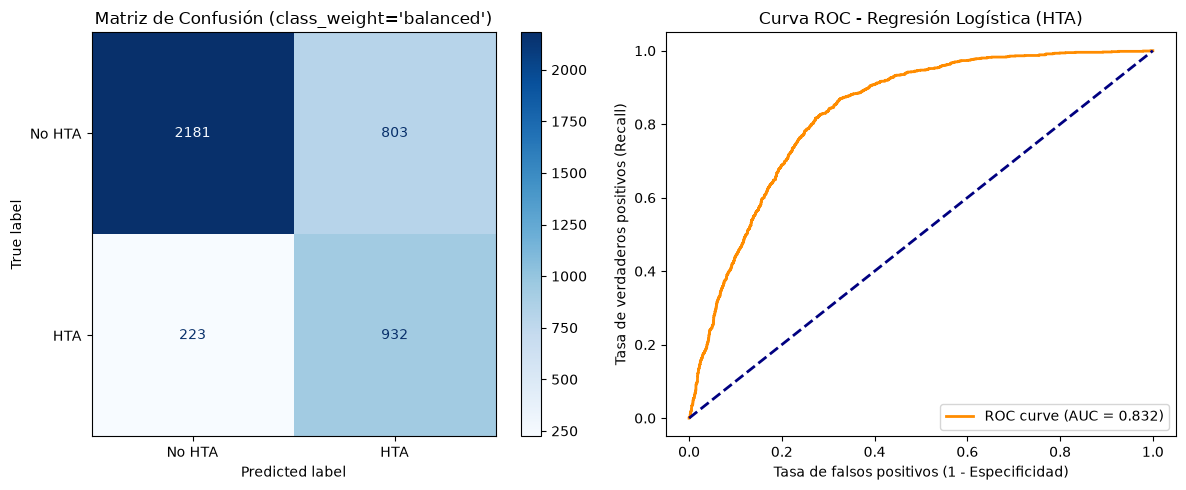

In [16]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_hta = reg_log_hta_class_weight.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [6]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta_class_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta_class_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8023 | Recall test: 0.8069
Diferencia: 0.0046


INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9262    0.6689    0.7768      2984
           1     0.5020    0.8623    0.6346      1155

    accuracy                         0.7229      4139
   macro avg     0.7141    0.7656    0.7057      4139
weighted avg     0.8078    0.7229    0.7371      4139

ROC-AUC Score: 0.8283


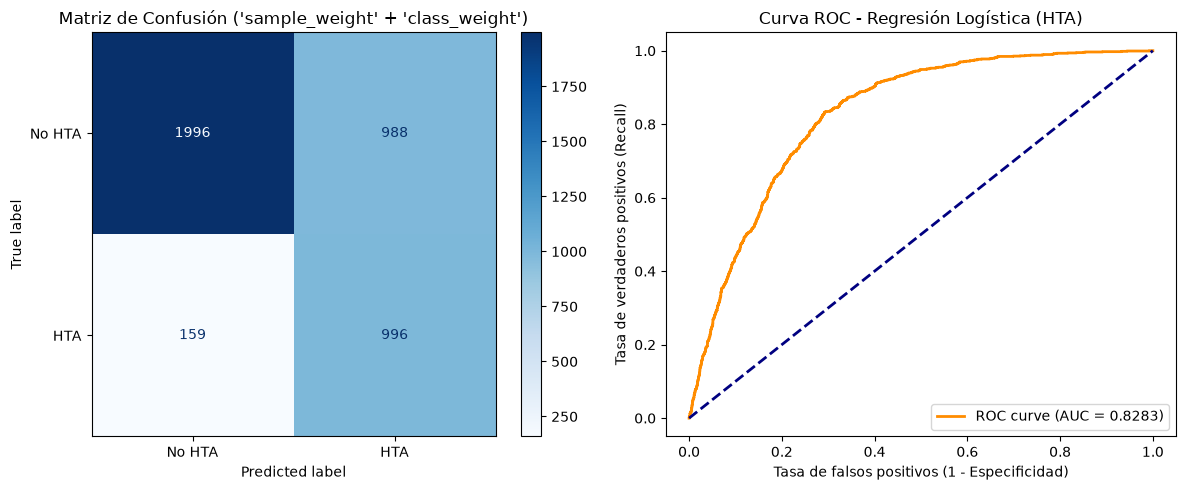

In [17]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_hta = reg_log_hta.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión ('sample_weight' + 'class_weight')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [7]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8539 | Recall test: 0.8623
Diferencia: 0.0085


In [18]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_hta >= u).astype(int)
    report = classification_report(
        y_test_hta, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]
    acc = report["accuracy"]

    print(f"Umbral {u:.2f} -> Recall HTA: {rec*100:.2f}% | Precisión HTA: {prec*100:.2f}% | F1: {f1:.2f}% | Accuracy Global: {acc*100:.2f}")

Umbral 0.35 -> Recall HTA: 93.25% | Precisión HTA: 43.98% | F1: 0.60% | Accuracy Global: 64.97
Umbral 0.40 -> Recall HTA: 91.60% | Precisión HTA: 46.04% | F1: 0.61% | Accuracy Global: 67.70
Umbral 0.45 -> Recall HTA: 88.92% | Precisión HTA: 47.95% | F1: 0.62% | Accuracy Global: 69.97
Umbral 0.50 -> Recall HTA: 86.23% | Precisión HTA: 50.20% | F1: 0.63% | Accuracy Global: 72.29
Umbral 0.55 -> Recall HTA: 82.94% | Precisión HTA: 52.41% | F1: 0.64% | Accuracy Global: 74.22


HIPERTENSIÓN CON SMOTE
              precision    recall  f1-score   support

           0     0.9025    0.7383    0.8122      2984
           1     0.5400    0.7939    0.6428      1155

    accuracy                         0.7538      4139
   macro avg     0.7213    0.7661    0.7275      4139
weighted avg     0.8014    0.7538    0.7649      4139

ROC-AUC Score: 0.8308


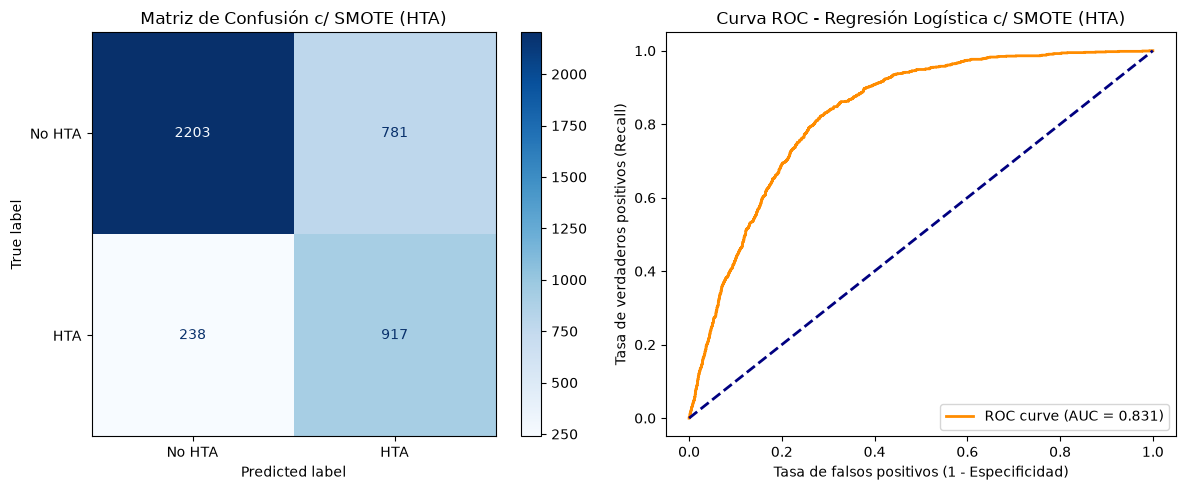

In [19]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_smote = reg_log_hta_smote.predict(X_test_hta)
y_proba_smote = reg_log_hta_smote.predict_proba(X_test_hta)[:, 1]

print("HIPERTENSIÓN CON SMOTE")
print(classification_report(y_test_hta, y_pred_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_hta, y_proba_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión c/ SMOTE (HTA)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_hta, y_proba_smote)
auc_smote = roc_auc_score(y_test_hta, y_proba_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística c/ SMOTE (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta_smote.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta_smote.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7948 | Recall test: 0.7939
Diferencia: 0.0008


### CONCLUSIONES METODOLÓGICAS 

- El modelo seleccionado como Baseline es la combinación de class_weight='balanced' + sample_weight (FACTORADULTO), el cual es la opción más robusta clínicamente. Este modelo logra reducir los Falsos Negativos a solo 159 casos, mientras que el modelo que solo usa class_weight este número aumenta a 223 y 238 para el modelo con SMOTE. 

- SMOTE vs. FACTORADULTO: SMOTE incrementa ligeramente la Esepcificidad y la precision, pero al no incluir el factor de elevación de la encuesta nacional, se pierde la capacidad de detección de enfermos (Recall cae a 79,39%)

- Por ultimo, el análisis de umbrales demuestra que la mejor opción sigue siendo class_weight="balanced", o sea, 0.50

# EVALUACIÓN RANDOM FOREST

In [10]:
# Cargar modelo Random Forest
import joblib 
rf_hta_class_weight = joblib.load("../models/random_forest_hta_class_weight.joblib")
rf_hta = joblib.load("../models/random_forest_hta.joblib")
rf_smote_hta = joblib.load("../models/rf_smote_hta.joblib")
rf_subsample_hta = joblib.load("../models/subsample_random_forest_hta.joblib")
brf_hta = joblib.load("../models/balanced_random_forest_hta.joblib")
brf_hta_sample_weight = joblib.load("../models/brf_hta_sample_weight.joblib")
brf_opt_gridsearch = joblib.load("../models/brf_hta_opt_gridsearch.joblib")

INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8712    0.7979    0.8330      2984
           1     0.5711    0.6952    0.6271      1155

    accuracy                         0.7693      4139
   macro avg     0.7212    0.7466    0.7300      4139
weighted avg     0.7875    0.7693    0.7755      4139

ROC-AUC Score: 0.8324


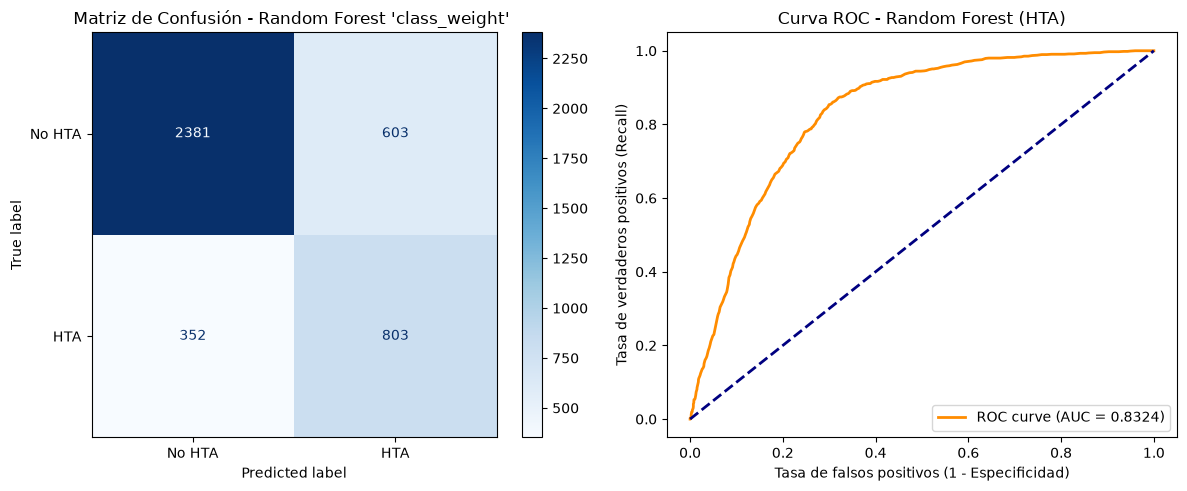

In [21]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - HIPERTENSIÓN
# ========================================================

# Predicciones 
y_pred_rf_hta_class_weight = rf_hta_class_weight.predict(X_test_hta)
y_proba_rf_hta_class_weight = rf_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_rf_hta_class_weight, digits=4))

# ROC-AUC 
auc_rf_hta_class_weight = roc_auc_score(y_test_hta, y_proba_rf_hta_class_weight)
print(f"ROC-AUC Score: {auc_rf_hta_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta_class_weight = confusion_matrix(y_test_hta, y_pred_rf_hta_class_weight)
disp_rf_hta_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta_class_weight, display_labels=["No HTA", "HTA"])
disp_rf_hta_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest 'class_weight' ")

# Curva ROC
fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, _ = roc_curve(y_test_hta, y_proba_rf_hta_class_weight)
axes[1].plot(fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [11]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_hta_class_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_hta_class_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.6952
Diferencia: 0.3048


INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO
              precision    recall  f1-score   support

           0     0.8801    0.7822    0.8282      2984
           1     0.5629    0.7247    0.6336      1155

    accuracy                         0.7661      4139
   macro avg     0.7215    0.7534    0.7309      4139
weighted avg     0.7916    0.7661    0.7739      4139

ROC-AUC Score: 0.8312


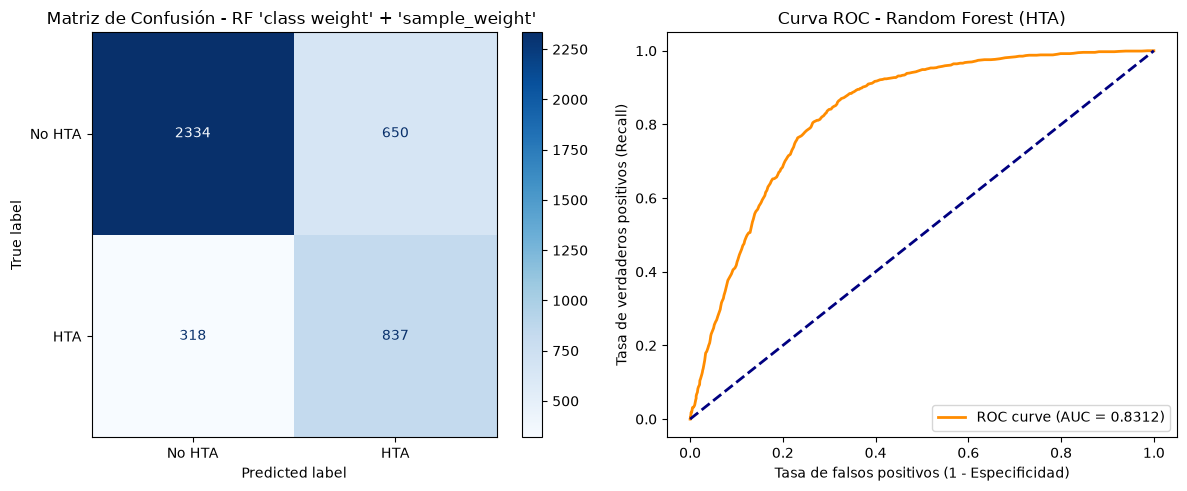

In [22]:
# ========================================================================
# EVALUACIÓN RANDOM FOREST ('class_weight' + FACTORADULTO) - HIPERTENSIÓN
# ========================================================================

# Predicciones 
y_pred_rf_hta = rf_hta.predict(X_test_hta)
y_proba_rf_hta = rf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO")
print(classification_report(y_test_hta, y_pred_rf_hta, digits=4))

# ROC-AUC 
auc_rf_hta = roc_auc_score(y_test_hta, y_proba_rf_hta)
print(f"ROC-AUC Score: {auc_rf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta = confusion_matrix(y_test_hta, y_pred_rf_hta)
disp_rf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta.astype(int), display_labels=["No HTA", "HTA"])
disp_rf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF 'class weight' + 'sample_weight' ")

# Curva ROC
fpr_rf_hta, tpr_rf_hta, _ = roc_curve(y_test_hta, y_proba_rf_hta)
axes[1].plot(fpr_rf_hta, tpr_rf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9909 | Recall test: 0.7247
Diferencia: 0.2662


INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.8253    0.8710    0.8475      2984
           1     0.6111    0.5238    0.5641      1155

    accuracy                         0.7741      4139
   macro avg     0.7182    0.6974    0.7058      4139
weighted avg     0.7656    0.7741    0.7685      4139

ROC-AUC Score: 0.8316


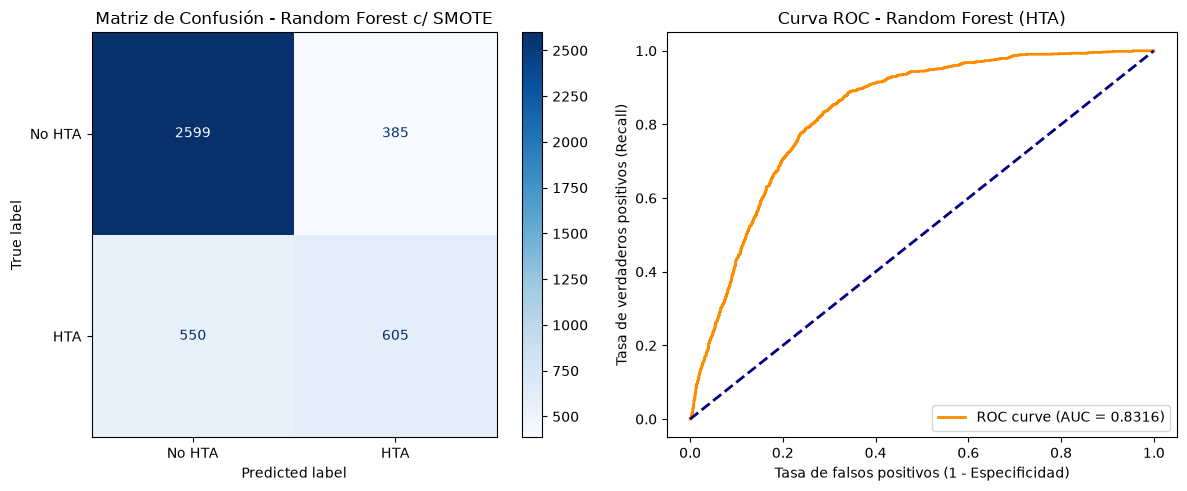

In [23]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_hta = rf_smote_hta.predict(X_test_hta)
y_proba_rf_smote_hta = rf_smote_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_hta, y_pred_rf_smote_hta, digits=4))

# ROC-AUC 
auc_rf_smote_hta = roc_auc_score(y_test_hta, y_proba_rf_smote_hta)
print(f"ROC-AUC Score: {auc_rf_smote_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_hta = confusion_matrix(y_test_hta, y_pred_rf_smote_hta)
disp_rf_smote_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_hta, display_labels=["No HTA", "HTA"])
disp_rf_smote_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest c/ SMOTE")

# Curva ROC
fpr_rf_smote_hta, tpr_rf_smote_hta, _ = roc_curve(y_test_hta, y_proba_rf_smote_hta)
axes[1].plot(fpr_rf_smote_hta, tpr_rf_smote_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_smote_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_smote_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.6099 | Recall test: 0.5238
Diferencia: 0.0861


INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.9053    0.7366    0.8123      2984
           1     0.5406    0.8009    0.6455      1155

    accuracy                         0.7545      4139
   macro avg     0.7229    0.7687    0.7289      4139
weighted avg     0.8035    0.7545    0.7657      4139

ROC-AUC Score: 0.8324


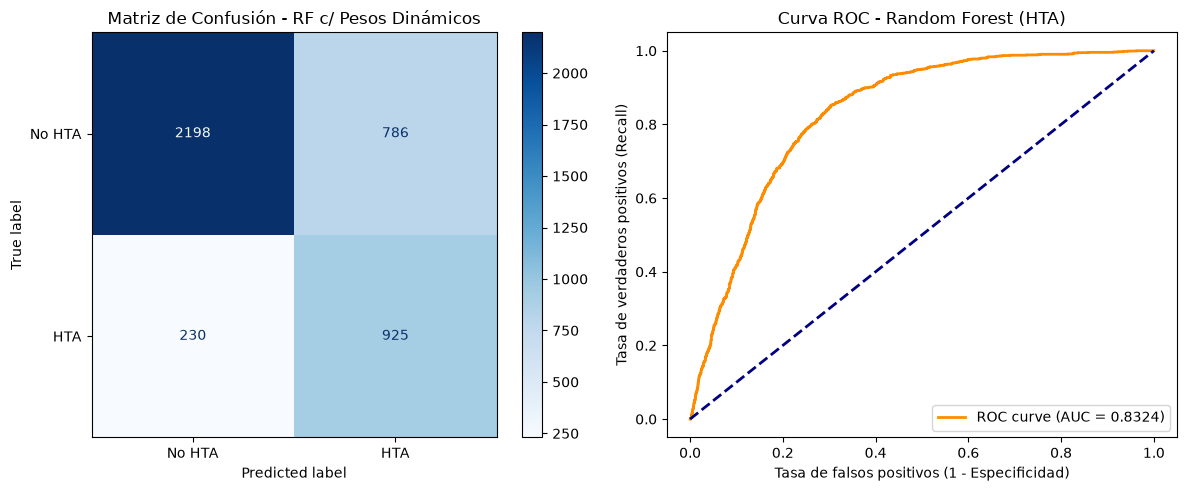

In [24]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample_hta.predict(X_test_hta)
y_proba_rf_subsample = rf_subsample_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_hta, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_hta, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_hta, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No HTA", "HTA"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF c/ Pesos Dinámicos")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_hta, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_hta_pesos_dinamicos.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_subsample_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_subsample_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8697 | Recall test: 0.8009
Diferencia: 0.0688


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8882    0.7664    0.8228      2984
           1     0.5543    0.7506    0.6377      1155

    accuracy                         0.7620      4139
   macro avg     0.7213    0.7585    0.7303      4139
weighted avg     0.7950    0.7620    0.7712      4139

ROC-AUC Score: 0.8314


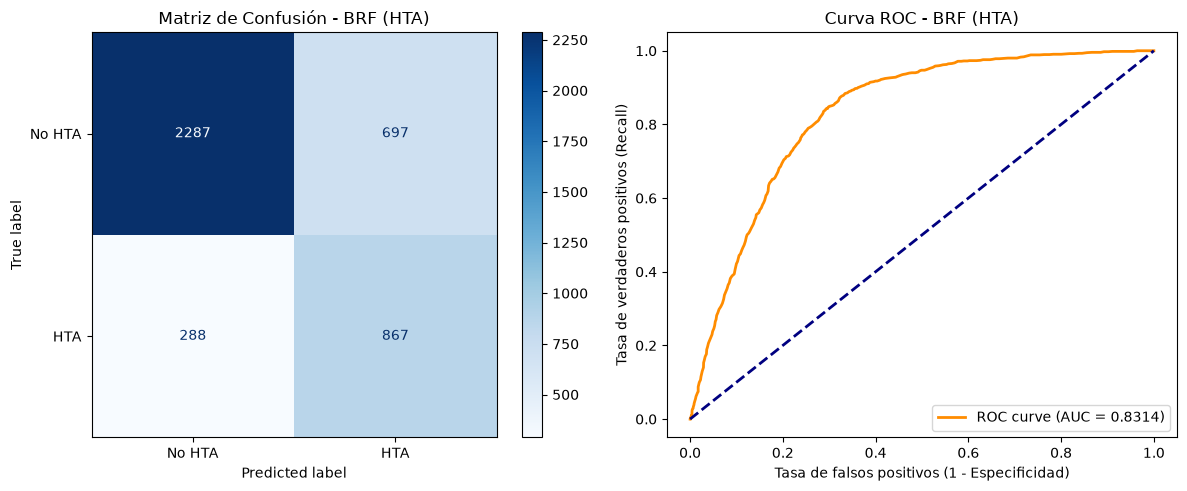

In [25]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_hta = brf_hta.predict(X_test_hta)
y_proba_brf_hta = brf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_brf_hta, digits=4))

# ROC-AUC 
auc_brf_hta = roc_auc_score(y_test_hta, y_proba_brf_hta)
print(f"ROC-AUC Score: {auc_brf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_hta = confusion_matrix(y_test_hta, y_pred_brf_hta)
disp_brf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_brf_hta, display_labels=["No HTA", "HTA"])
disp_brf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF (HTA)")

# Curva ROC
fpr_brf_hta, tpr_brf_hta, _ = roc_curve(y_test_hta, y_proba_brf_hta)
axes[1].plot(fpr_brf_hta, tpr_brf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.7506
Diferencia: 0.2494


,Umbral,Recall HTA,Precisión HTA,F1-Score,FN (Enfermos No Detectados),FP (Sanos Clasificados como Enfermos)
0,0.20,98.18%,36.43%,0.5314,21,1979
1,0.25,96.45%,39.32%,0.5587,41,1719
2,0.30,94.55%,42.26%,0.5841,63,1492
3,0.35,92.73%,44.81%,0.6042,84,1319
4,0.40,91.26%,47.50%,0.6248,101,1165
5,0.45,88.66%,49.83%,0.6380,131,1031
6,0.50,84.16%,51.84%,0.6416,183,903


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO
              precision    recall  f1-score   support

           0     0.9192    0.6974    0.7931      2984
           1     0.5184    0.8416    0.6416      1155

    accuracy                         0.7376      4139
   macro avg     0.7188    0.7695    0.7173      4139
weighted avg     0.8073    0.7376    0.7508      4139

ROC-AUC Score: 0.8327


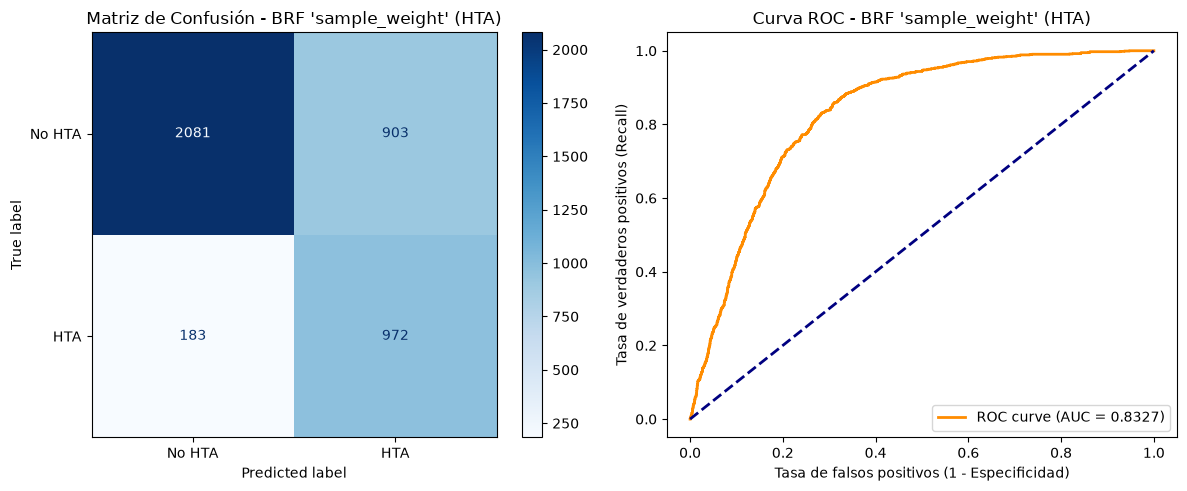

In [26]:
# =============================================
# EVALUACIÓN Balanced Random Forest 'sample_weight'
# =============================================

# Predicciones 
y_pred_hta_sample_weight = brf_hta_sample_weight.predict(X_test_hta)
y_proba_hta_sample_weight = brf_hta_sample_weight.predict_proba(X_test_hta)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_hta_sample_weight >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    rep = classification_report(y_test_hta, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall HTA": f"{rep['1']['recall']*100:.2f}%",
            "Precisión HTA": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos No Detectados)": int(fn),
            "FP (Sanos Clasificados como Enfermos)": int(fp)
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO")
print(classification_report(y_test_hta, y_pred_hta_sample_weight, digits=4))

# ROC-AUC 
auc_hta_sample_weight = roc_auc_score(y_test_hta, y_proba_hta_sample_weight)
print(f"ROC-AUC Score: {auc_hta_sample_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_hta_sample_weight = confusion_matrix(y_test_hta, y_pred_hta_sample_weight)
disp_hta_sample_weight = ConfusionMatrixDisplay(confusion_matrix=cm_hta_sample_weight, display_labels=["No HTA", "HTA"])
disp_hta_sample_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF 'sample_weight' (HTA)")

# Curva ROC
fpr_hta_sample_weight, tpr_hta_sample_weight, _ = roc_curve(y_test_hta, y_proba_hta_sample_weight)
axes[1].plot(fpr_hta_sample_weight, tpr_hta_sample_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta_sample_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF 'sample_weight' (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_hta_sample_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [17]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_hta_sample_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_hta_sample_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9047 | Recall test: 0.8416
Diferencia: 0.0632


In [27]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular el umbral exacto según el Índice de Youden
fpr, tpr, thresholds = roc_curve(
    y_test_hta, brf_hta_sample_weight.predict_proba(X_test_hta)[:, 1]
)
umbral_exacto = thresholds[np.argmax(tpr - fpr)]

print(f"Umbral exacto de Youden: {umbral_exacto:.2f}")

Umbral exacto de Youden: 0.49


,Umbral,Recall HTA,Precisión HTA,F1-Score,FN (Enfermos No Detectados),FP (Sanos Clasificados como Enfermos)
0,0.20,97.75%,35.13%,0.5168,26,2085
1,0.25,96.28%,37.87%,0.5436,43,1824
2,0.30,94.89%,40.64%,0.5691,59,1601
3,0.35,92.47%,43.27%,0.5896,87,1400
4,0.40,90.13%,45.86%,0.6079,114,1229
5,0.45,87.10%,48.60%,0.6239,149,1064
6,0.50,82.16%,50.29%,0.6239,206,938
7,0.60,70.22%,54.47%,0.6135,344,678


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO
              precision    recall  f1-score   support

           0     0.9085    0.6857    0.7815      2984
           1     0.5029    0.8216    0.6239      1155

    accuracy                         0.7236      4139
   macro avg     0.7057    0.7537    0.7027      4139
weighted avg     0.7953    0.7236    0.7375      4139

ROC-AUC Score: 0.8174


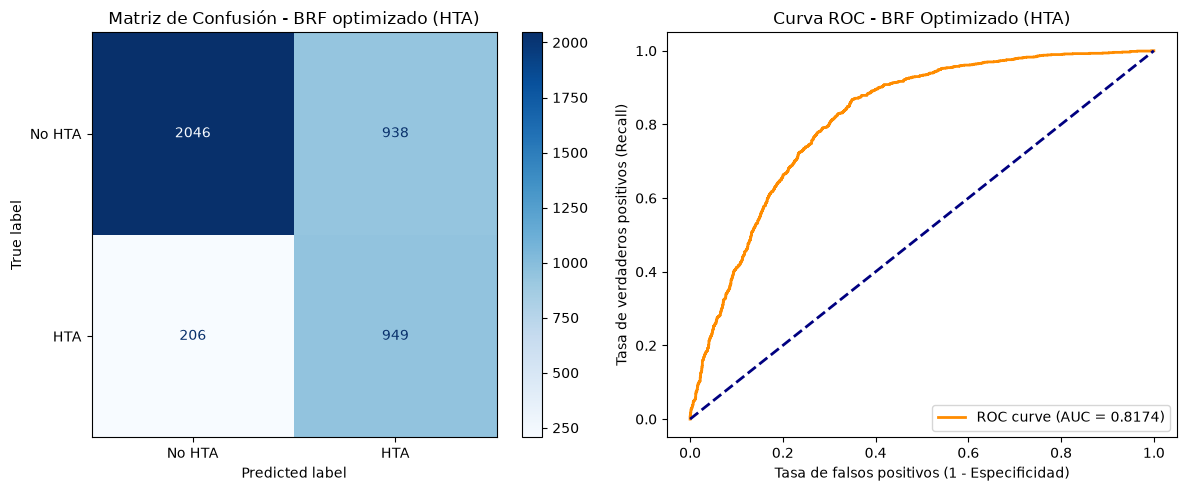

In [28]:

# ========================================================
# EVALUACIÓN Balanced Random Forest optimizado GridSearch
# ========================================================

# Predicciones 
y_pred_opt_gridsearch = brf_opt_gridsearch.predict(X_test_hta)
y_proba_opt_gridsearch = brf_opt_gridsearch.predict_proba(X_test_hta)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_opt_gridsearch >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    rep = classification_report(y_test_hta, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall HTA": f"{rep['1']['recall']*100:.2f}%",
            "Precisión HTA": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos No Detectados)": int(fn),
            "FP (Sanos Clasificados como Enfermos)": int(fp)
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO")
print(classification_report(y_test_hta, y_pred_opt_gridsearch, digits=4))

# ROC-AUC 
auc_opt_hta_gridsearch = roc_auc_score(y_test_hta, y_proba_opt_gridsearch)
print(f"ROC-AUC Score: {auc_opt_hta_gridsearch:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_opt_hta_gridsearch = confusion_matrix(y_test_hta, y_pred_opt_gridsearch)
disp_opt_hta_gridsearch = ConfusionMatrixDisplay(confusion_matrix=cm_opt_hta_gridsearch, display_labels=["No HTA", "HTA"])
disp_opt_hta_gridsearch.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF optimizado (HTA)")

# Curva ROC
fpr_opt_hta_gridsearch, tpr_opt_hta_gridsearch, _ = roc_curve(y_test_hta, y_proba_opt_gridsearch)
axes[1].plot(fpr_opt_hta_gridsearch, tpr_opt_hta_gridsearch, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_opt_hta_gridsearch:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF Optimizado (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [18]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_opt_gridsearch.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_opt_gridsearch.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8114 | Recall test: 0.8216
Diferencia: 0.0102


In [29]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular el umbral exacto según el Índice de Youden
fpr, tpr, thresholds = roc_curve(
    y_test_hta, brf_opt_gridsearch.predict_proba(X_test_hta)[:, 1]
)
umbral_exacto = thresholds[np.argmax(tpr - fpr)]

print(f"Umbral exacto de Youden: {umbral_exacto:.2f}")

Umbral exacto de Youden: 0.46


# SVM

In [19]:
# Cargar datos 
svm_hta_cw = joblib.load("../models/svm_hta_cw.joblib")
svm_hta = joblib.load("../models/svm_hta.joblib")
svm_hta_smote = joblib.load("../models/svm_hta_smote")
svm_hta_opt = joblib.load("../models/svm_hta_optimizado.joblib")

INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.9121    0.7061    0.7960      2984
           1     0.5205    0.8242    0.6381      1155

    accuracy                         0.7391      4139
   macro avg     0.7163    0.7652    0.7170      4139
weighted avg     0.8028    0.7391    0.7519      4139

ROC-AUC Score: 0.8241


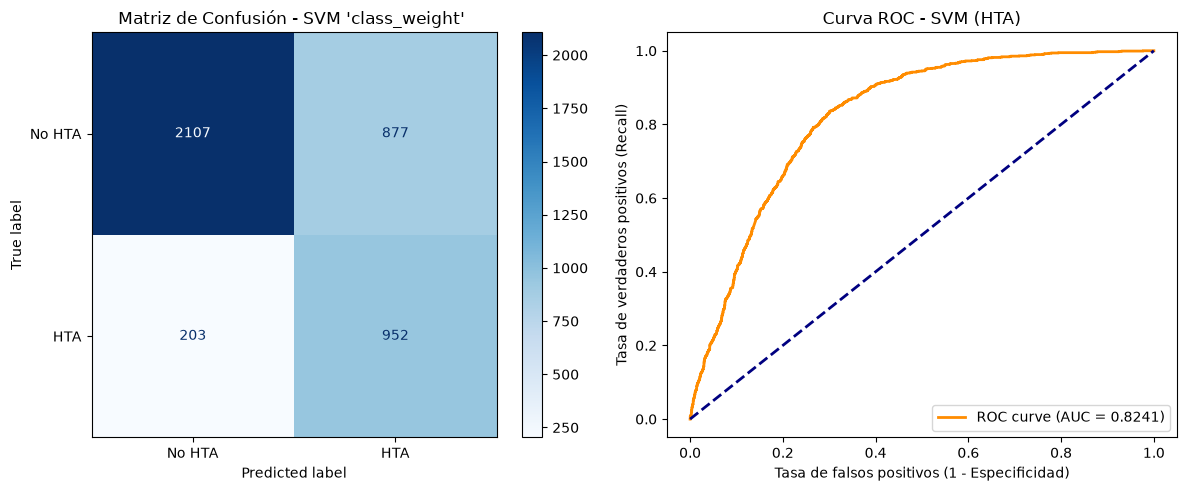

In [ ]:
# ==============================================
# EVALUACIÓN SVM 'class_weight' - HIPERTENSIÓN
# ==============================================

# Predicciones 
y_pred_svm_hta_cw = svm_hta_cw.predict(X_test_hta)
y_pred_proba_svm_hta_cw = svm_hta_cw.predict_proba(X_test_hta)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_cw, digits=4))

# ROC-AUC
auc_svm_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_cw)
print(f"ROC-AUC Score: {auc_svm_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_cw = confusion_matrix(y_test_hta,y_pred_svm_hta_cw)
disp_svm_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_cw, display_labels=["No HTA", "HTA"])
disp_svm_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' ")

# CURVA ROC 
fpr_svm_hta_cw, tpr_svm_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_cw)
axes[1].plot(fpr_svm_hta_cw, tpr_svm_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_cw.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_cw.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9063 | Recall test: 0.8242
Diferencia: 0.0820


INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.8936    0.7235    0.7996      2984
           1     0.5212    0.7775    0.6240      1155

    accuracy                         0.7386      4139
   macro avg     0.7074    0.7505    0.7118      4139
weighted avg     0.7897    0.7386    0.7506      4139

ROC-AUC Score: 0.8212


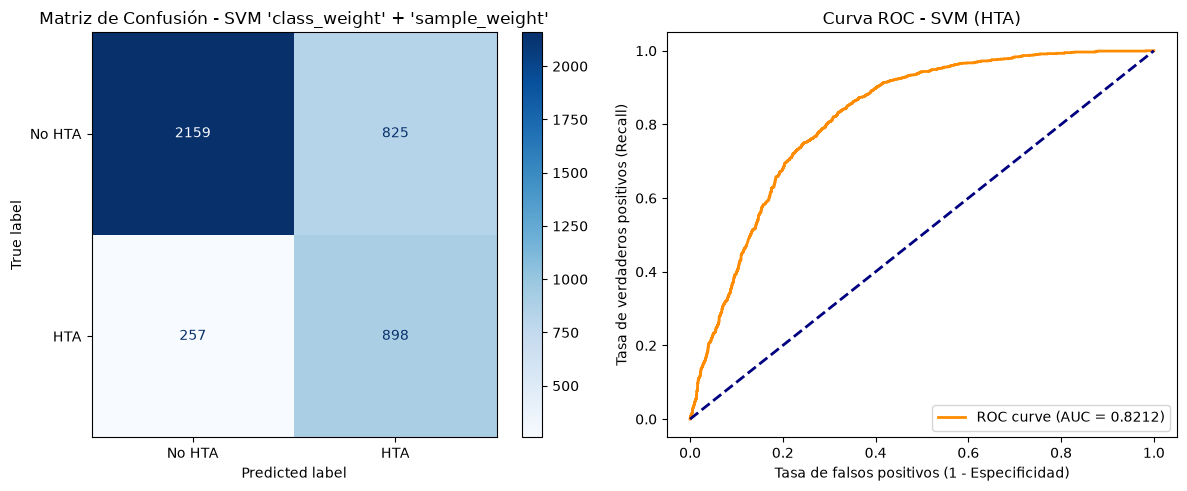

In [32]:
# ===============================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight' - HIPERTENSIÓN
# ===============================================================

# Predicciones 
y_pred_svm_hta = svm_hta.predict(X_test_hta)
y_pred_proba_svm_hta = svm_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta, digits=4))

# ROC-AUC
auc_svm_hta = roc_auc_score(y_test_hta, y_pred_proba_svm_hta)
print(f"ROC-AUC Score: {auc_svm_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta = confusion_matrix(y_test_hta,y_pred_svm_hta)
disp_svm_hta = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta, display_labels=["No HTA", "HTA"])
disp_svm_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' + 'sample_weight'")

# CURVA ROC 
fpr_svm_hta, tpr_svm_hta, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta)
axes[1].plot(fpr_svm_hta, tpr_svm_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8863 | Recall test: 0.7775
Diferencia: 0.1088


INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8389    0.8358    0.8373      2984
           1     0.5798    0.5853    0.5825      1155

    accuracy                         0.7659      4139
   macro avg     0.7093    0.7105    0.7099      4139
weighted avg     0.7666    0.7659    0.7662      4139

ROC-AUC Score: 0.8191


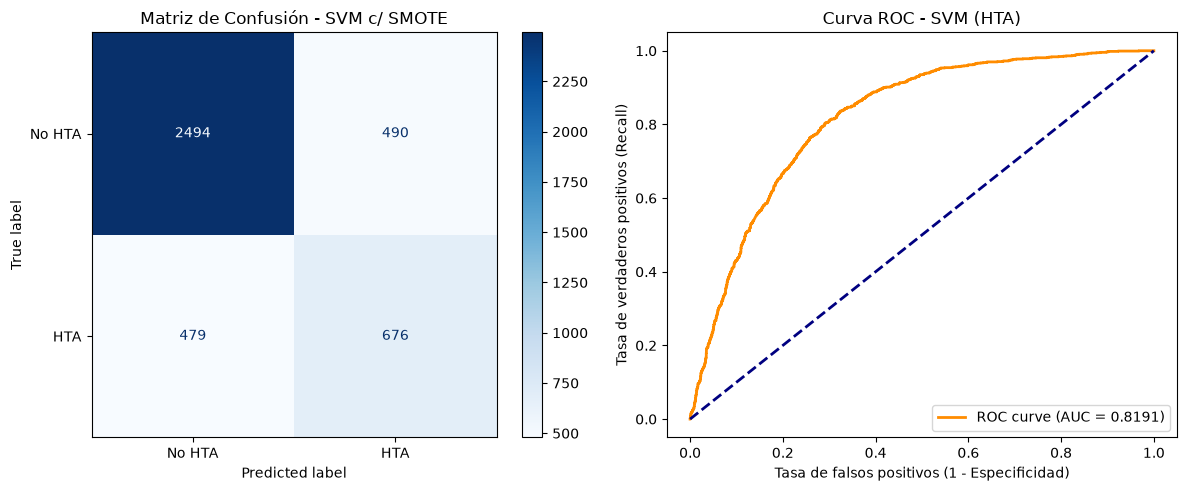

In [33]:
# ========================
# EVALUACIÓN SVM CON SMOTE
# ========================

# Predicciones 
y_pred_svm_hta_smote = svm_hta_smote.predict(X_test_hta)
y_pred_proba_svm_hta_smote = svm_hta_smote.predict_proba(X_test_hta)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_smote, digits=4))

# ROC-AUC
auc_svm_hta_smote = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_smote)
print(f"ROC-AUC Score: {auc_svm_hta_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_smote = confusion_matrix(y_test_hta,y_pred_svm_hta_smote)
disp_svm_hta_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_smote, display_labels=["No HTA", "HTA"])
disp_svm_hta_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM c/ SMOTE")

# CURVA ROC 
fpr_svm_hta_smote, tpr_svm_hta_smote, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_smote)
axes[1].plot(fpr_svm_hta_smote, tpr_svm_hta_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_smote.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_smote.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7270 | Recall test: 0.5853
Diferencia: 0.1417


INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO(HTA)
              precision    recall  f1-score   support

           0     0.9175    0.6971    0.7922      2984
           1     0.5171    0.8381    0.6396      1155

    accuracy                         0.7364      4139
   macro avg     0.7173    0.7676    0.7159      4139
weighted avg     0.8058    0.7364    0.7496      4139

ROC-AUC Score: 0.8326


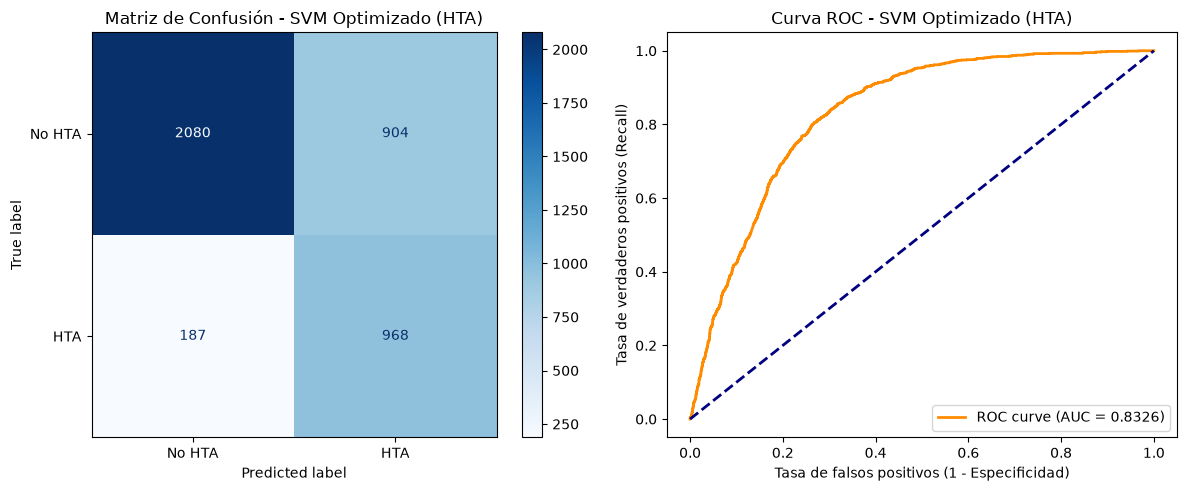

In [34]:
# ==============================================
# EVALUACIÓN SVM OPTIMIZADO - HIPERTENSIÓN
# ==============================================

# Predicciones 
y_pred_svm_hta_opt = svm_hta_opt.predict(X_test_hta)
y_pred_proba_svm_hta_opt = svm_hta_opt.predict_proba(X_test_hta)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO(HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_opt, digits=4))

# ROC-AUC
auc_svm_hta_opt = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_opt)
print(f"ROC-AUC Score: {auc_svm_hta_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_opt = confusion_matrix(y_test_hta,y_pred_svm_hta_opt)
disp_svm_hta_opt = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_opt, display_labels=["No HTA", "HTA"])
disp_svm_hta_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM Optimizado (HTA)")

# CURVA ROC 
fpr_svm_hta_opt, tpr_svm_hta_opt, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_opt)
axes[1].plot(fpr_svm_hta_opt, tpr_svm_hta_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_opt:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM Optimizado (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_opt.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_opt.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8547 | Recall test: 0.8381
Diferencia: 0.0166


In [35]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Probabilidades predichas del SVM optimizado
y_pred_proba_svm_hta_opt = svm_hta_opt.predict_proba(X_test_hta)[:, 1]

# Rango extendido de umbrales
umbrales = [0.10, 0.15, 0.20, 0.25, 0.26, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_svm = []

for u in umbrales:
    y_pred_u = (y_pred_proba_svm_hta_opt >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    report = classification_report(y_test_hta, y_pred_u, output_dict=True)

    evaluacion_svm.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_svm = pd.DataFrame(evaluacion_svm)
display(df_umbrales_svm)

# Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_hta, y_pred_proba_svm_hta_opt)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.10,0.9628,0.4087,0.5738,43,1609
1,0.15,0.9316,0.4489,0.6059,79,1321
2,0.20,0.8900,0.4810,0.6245,127,1109
3,0.25,0.8476,0.5123,0.6386,176,932
4,0.26,0.8381,0.5165,0.6392,187,906
5,0.30,0.8009,0.5390,0.6444,230,791
6,0.35,0.7403,0.5621,0.6390,300,666
7,0.40,0.6762,0.5798,0.6243,374,566
8,0.45,0.5974,0.5897,0.5935,465,480
9,0.50,0.5290,0.5990,0.5618,544,409



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.24


# EVALUACIÓN MODELOS XGBOOST

In [24]:
# CARGAR DATOS

import joblib

xgb_model_cw_hta = joblib.load("../models/xgb_model_cw_hta.joblib")
xgb_model_hta = joblib.load("../models/xgb_model_hta.joblib")
xgb_model_smote_hta = joblib.load("../models/xgb_model_smote_hta.joblib")
xgb_hta_opt = joblib.load("../models/xgb_hta_optimizado.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)
              precision    recall  f1-score   support

           0     0.9068    0.7239    0.8051      2984
           1     0.5310    0.8078    0.6408      1155

    accuracy                         0.7473      4139
   macro avg     0.7189    0.7658    0.7229      4139
weighted avg     0.8019    0.7473    0.7592      4139

ROC-AUC Score: 0.8308


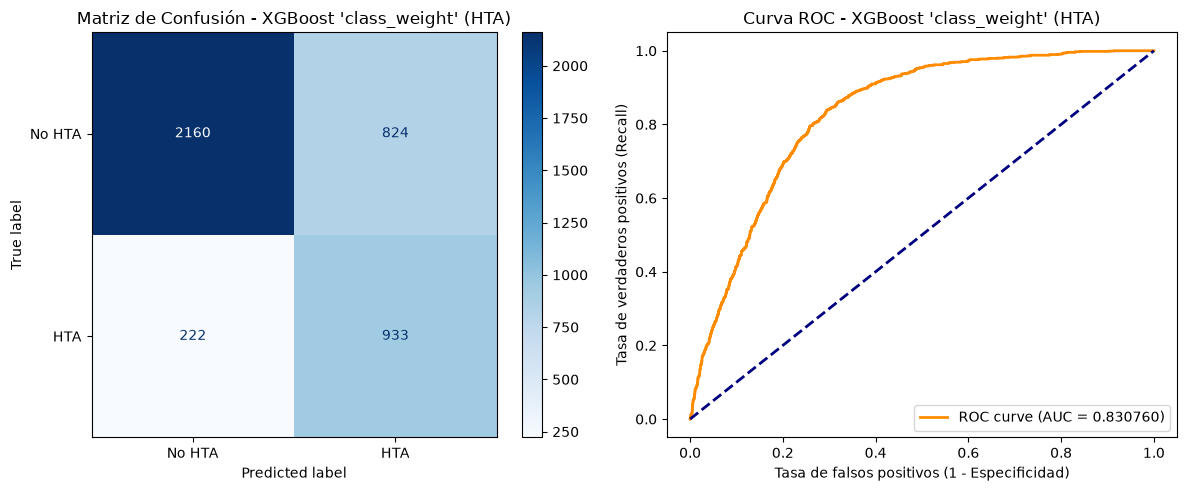

In [37]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - HIPERTENSIÓN
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta_cw = xgb_model_cw_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta_cw = xgb_model_cw_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta_cw, digits=4))

# ROC-AUC
auc_xgb_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta_cw)
print(f"ROC-AUC Score: {auc_xgb_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta_cw = confusion_matrix(y_test_hta, y_pred_xgb_hta_cw)
disp_xgb_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta_cw, display_labels=["No HTA", "HTA"])
disp_xgb_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost 'class_weight' (HTA)")

# Curva ROC
fpr_xgb_hta_cw, tpr_xgb_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta_cw)
axes[1].plot(fpr_xgb_hta_cw, tpr_xgb_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta_cw:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost 'class_weight' (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/xgb_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_cw_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_cw_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8931 | Recall test: 0.8078
Diferencia: 0.0853


INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)
              precision    recall  f1-score   support

           0     0.9022    0.7386    0.8122      2984
           1     0.5401    0.7931    0.6426      1155

    accuracy                         0.7538      4139
   macro avg     0.7211    0.7658    0.7274      4139
weighted avg     0.8011    0.7538    0.7649      4139

ROC-AUC Score: 0.8295


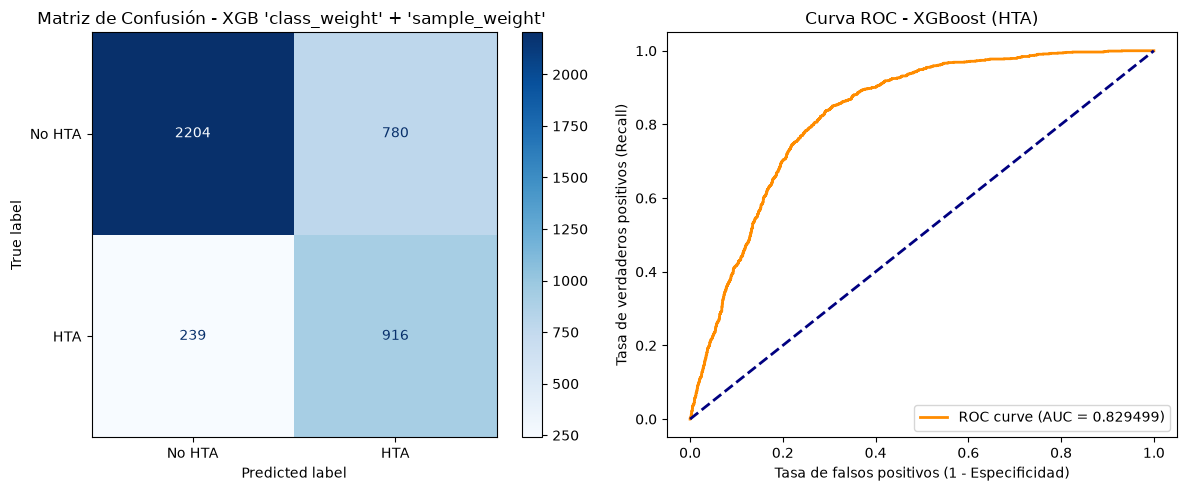

In [38]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - HIPERTENSIÓN
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta = xgb_model_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta = xgb_model_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta, digits=4))

# ROC-AUC
auc_xgb_hta = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta)
print(f"ROC-AUC Score: {auc_xgb_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta = confusion_matrix(y_test_hta, y_pred_xgb_hta)
disp_xgb_hta = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta, display_labels=["No HTA", "HTA"])
disp_xgb_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGB 'class_weight' + 'sample_weight' ")

# Curva ROC
fpr_xgb_hta, tpr_xgb_hta, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta)
axes[1].plot(fpr_xgb_hta, tpr_xgb_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8855 | Recall test: 0.7931
Diferencia: 0.0924


INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8439    0.8458    0.8449      2984
           1     0.5993    0.5957    0.5975      1155

    accuracy                         0.7760      4139
   macro avg     0.7216    0.7208    0.7212      4139
weighted avg     0.7756    0.7760    0.7758      4139

ROC-AUC Score: 0.8315


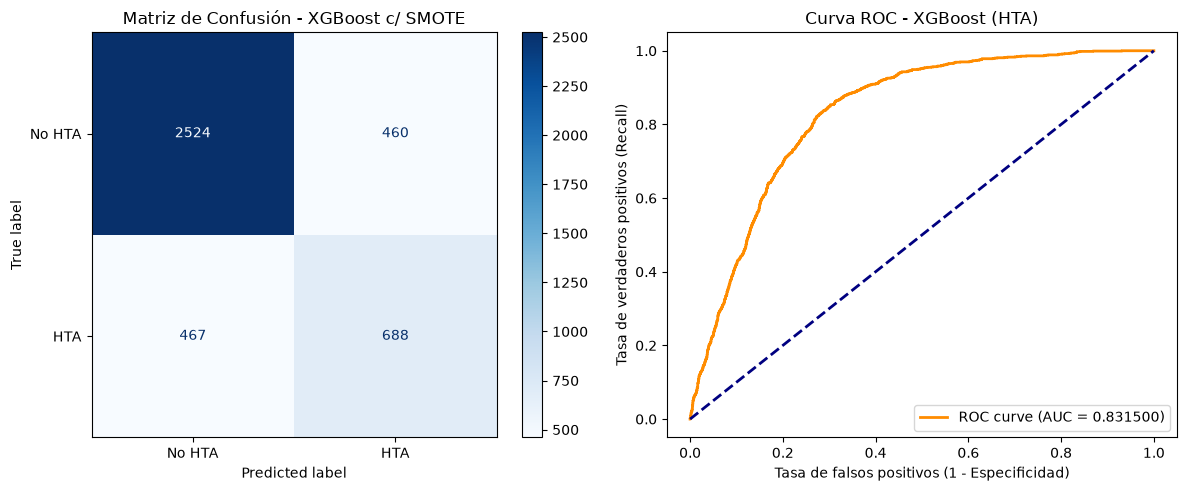

In [39]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================


# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_smote = xgb_model_smote_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_hta, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_hta, y_pred_xgb_smote)
disp_xgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No HTA", "HTA"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost c/ SMOTE")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_hta, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_smote_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_smote_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.6649 | Recall test: 0.5957
Diferencia: 0.0692


INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)
              precision    recall  f1-score   support

           0     0.9220    0.7051    0.7991      2984
           1     0.5261    0.8459    0.6487      1155

    accuracy                         0.7444      4139
   macro avg     0.7241    0.7755    0.7239      4139
weighted avg     0.8115    0.7444    0.7571      4139

ROC-AUC Score: 0.8356


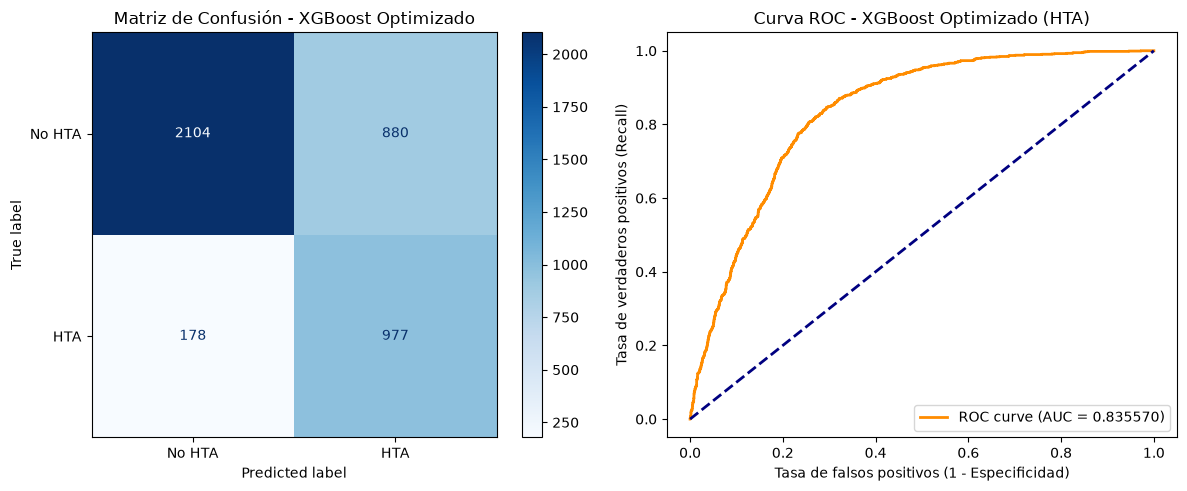

In [40]:
# ===========================================================
# EVALUACIÓN XGBOOST OPTIMIZADO - HIPERTENSIÓN
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta_opt = xgb_hta_opt.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta_opt = xgb_hta_opt.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta_opt, digits=4))

# ROC-AUC
auc_xgb_hta_opt = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta_opt)
print(f"ROC-AUC Score: {auc_xgb_hta_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta_opt = confusion_matrix(y_test_hta, y_pred_xgb_hta_opt)
disp_xgb_hta_opt = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta_opt, display_labels=["No HTA", "HTA"])
disp_xgb_hta_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Optimizado")

# Curva ROC
fpr_xgb_hta_opt, tpr_xgb_hta_opt, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta_opt)
axes[1].plot(fpr_xgb_hta_opt, tpr_xgb_hta_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta_opt:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Optimizado (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_hta_opt.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_hta_opt.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8376 | Recall test: 0.8459
Diferencia: 0.0083


In [41]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_proba_opt = xgb_hta_opt.predict_proba(X_test_hta)[:, 1]
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_umbrales = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)

    # Extraer directamente la matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    report = classification_report(y_test_hta, y_pred_u, output_dict=True)

    evaluacion_umbrales.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_corregido = pd.DataFrame(evaluacion_umbrales)
display(df_umbrales_corregido)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.20,0.9628,0.4066,0.5717,43,1623
1,0.25,0.9463,0.4317,0.5929,62,1439
2,0.30,0.9247,0.4549,0.6098,87,1280
3,0.35,0.9100,0.4705,0.6202,104,1183
4,0.40,0.8987,0.4806,0.6262,117,1122
5,0.45,0.8797,0.5010,0.6384,139,1012
6,0.50,0.8459,0.5261,0.6487,178,880


En cribado de salud (screening), el Índice de Youden (J = Sensibilidad + Especificidad - 1) busca el punto geométrico de máxima separación entre enfermos y sanos en la curva ROC.

In [42]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular FPR, TPR y umbrales de la curva ROC
fpr, tpr, thresholds = roc_curve(y_test_hta, y_proba_opt)

# Índice de Youden: J = Sensibilidad - FPR (ya que FPR = 1 - Especificidad)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
opt_threshold = thresholds[opt_idx]

print(f"El umbral óptimo según el Índice de Youden es: {opt_threshold:.2f}")

El umbral óptimo según el Índice de Youden es: 0.50


# EVALUACIÓN POR MODELO

In [51]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

#  Función de coloración
def colorear_metricas(val, metrica):
    if pd.isna(val):
        return ''
    
    if metrica == 'ROC-AUC Test':
        if val < 0.60: return 'background-color: #f8d7da; color: #721c24;'
        elif val < 0.70: return 'background-color: #ffeba8; color: #856404;'
        elif val < 0.80: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #28a745; color: white;'

    elif metrica == 'Recall Test':
        if val >= 0.80: return 'background-color: #28a745; color: white;'
        elif val >= 0.60: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #f8d7da; color: #721c24;'

    elif metrica == 'Precision Test':
        if val < 0.20: return 'background-color: #f8d7da; color: #721c24;'
        return ''

    elif metrica == 'F1-Score Test':
        if val < 0.50: return 'background-color: #f8d7da; color: #721c24;'
        elif val <= 0.65: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    elif metrica == 'Dif. Recall (Train - Test)':
        mag = abs(val)
        if mag > 0.10: return 'background-color: #f8d7da; color: #721c24;'
        elif mag >= 0.05: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    return ''

# 2. Función reutilizable para generar y estilizar la tabla
def generar_tabla_comparativa(diccionario_modelos, X_train, y_train, X_test, y_test):
    resultados = []

    for nombre, modelo in diccionario_modelos.items():
        y_pred_train = modelo.predict(X_train)
        y_pred_test = modelo.predict(X_test)
        y_proba_test = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
        
        acc_test = accuracy_score(y_test, y_pred_test)
        recall_train = recall_score(y_train, y_pred_train)
        recall_test = recall_score(y_test, y_pred_test)
        diff_recall = recall_train - recall_test 
        
        resultados.append({
            'Modelo': nombre,
            'Accuracy Test': round(acc_test, 4),
            'Recall Test': round(recall_test, 4),
            'Dif. Recall (Train - Test)': round(diff_recall, 4),
            'Precision Test': round(precision_score(y_test, y_pred_test), 4),
            'F1-Score Test': round(f1_score(y_test, y_pred_test), 4),
            'ROC-AUC Test': round(roc_auc_score(y_test, y_proba_test), 4)
        })

    df = pd.DataFrame(resultados).sort_values(by='ROC-AUC Test', ascending=False).reset_index(drop=True)

    styler = df.style.format({
        'Accuracy Test': '{:.4f}',
        'Recall Test': '{:.4f}',
        'Dif. Recall (Train - Test)': '{:.4f}',
        'Precision Test': '{:.4f}',
        'F1-Score Test': '{:.4f}',
        'ROC-AUC Test': '{:.4f}'
    })

    for col in df.columns:
        if col != 'Modelo':
            styler = styler.map(lambda v, c=col: colorear_metricas(v, c), subset=[col])

    return styler

In [69]:
import os
import dataframe_image as dfi

# 1. Definir los modelos
modelos_rl_hta = {
    'Regresión Logística (Class Weight)': reg_log_hta_class_weight,
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_hta,
    'Regresión Logística (SMOTE)': reg_log_hta_smote
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_rl_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_regresion_logistica.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight),0.7521,0.8069,-0.0046,0.5372,0.6450,0.8321
1,Regresión Logística (SMOTE),0.7538,0.7939,0.0008,0.5400,0.6428,0.8308
2,Regresión Logística (Class Weight + Sample Weight),0.7229,0.8623,-0.0085,0.5020,0.6346,0.8283


In [67]:
modelos_rf_hta = {
    'Random Forest (Class Weight)': rf_hta_class_weight,
    'Random Forest (Class Weight + Sample Weight)': rf_hta,
    'Random Forest (SMOTE)': rf_smote_hta,
    'Random Forest c/ pesos dinámicos': rf_subsample_hta,
    'Balanced Random Forest': brf_hta,
    'Balanced Random Forest (Sample Weight)': brf_hta_sample_weight,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch
    }

# Generar la tabla coloreada reutilizando la función
tabla_estilizada = generar_tabla_comparativa(modelos_rf_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_random_forest.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Balanced Random Forest (Sample Weight),0.7376,0.8416,0.0632,0.5184,0.6416,0.8327
1,Random Forest c/ pesos dinámicos,0.7545,0.8009,0.0688,0.5406,0.6455,0.8324
2,Random Forest (Class Weight),0.7693,0.6952,0.3048,0.5711,0.6271,0.8324
3,Random Forest (SMOTE),0.7741,0.5238,0.0861,0.6111,0.5641,0.8316
4,Balanced Random Forest,0.7620,0.7506,0.2494,0.5543,0.6377,0.8314
5,Random Forest (Class Weight + Sample Weight),0.7661,0.7247,0.2662,0.5629,0.6336,0.8312
6,Balanced Random Forest Optimizado,0.7236,0.8216,-0.0102,0.5029,0.6239,0.8174


In [66]:
modelos_svm_hta = {
    'SVM (Class Weight)': svm_hta_cw,
    'SVM (Class Weight + Sample Weight)': svm_hta,
    'SVM (SMOTE)': svm_hta_smote,
    'SVM Optimizado': svm_hta_opt
}

tabla_estilizada = generar_tabla_comparativa(modelos_svm_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_svm.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,SVM Optimizado,0.7364,0.8381,0.0166,0.5171,0.6396,0.8326
1,SVM (Class Weight),0.7391,0.8242,0.0820,0.5205,0.6381,0.8241
2,SVM (Class Weight + Sample Weight),0.7386,0.7775,0.1088,0.5212,0.6240,0.8212
3,SVM (SMOTE),0.7659,0.5853,0.1417,0.5798,0.5825,0.8191


In [65]:
modelos_xgb_hta ={
    'XGBoost (Class Weight)': xgb_model_cw_hta,
    'XGBoost (Class Weight + Sample Weight)': xgb_model_hta,
    'XGBoost (SMOTE)': xgb_model_smote_hta,
    'XGBoost Optimizado': xgb_hta_opt
}


# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_xgb_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_xgboost.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7444,0.8459,-0.0083,0.5261,0.6487,0.8356
1,XGBoost (SMOTE),0.7760,0.5957,0.0692,0.5993,0.5975,0.8315
2,XGBoost (Class Weight),0.7473,0.8078,0.0853,0.5310,0.6408,0.8308
3,XGBoost (Class Weight + Sample Weight),0.7538,0.7931,0.0924,0.5401,0.6426,0.8295


# TABLA COMPARATIVA DE MEJORES RESULTADOS POR MODELO

In [70]:
tabla_comparativa_final = {
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_hta,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch,
    'SVM Optimizado': svm_hta_opt,
    'XGBoost Optimizado': xgb_hta_opt
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(tabla_comparativa_final, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'tabla_comparativa_final.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7444,0.8459,-0.0083,0.5261,0.6487,0.8356
1,SVM Optimizado,0.7364,0.8381,0.0166,0.5171,0.6396,0.8326
2,Regresión Logística (Class Weight + Sample Weight),0.7229,0.8623,-0.0085,0.5020,0.6346,0.8283
3,Balanced Random Forest Optimizado,0.7236,0.8216,-0.0102,0.5029,0.6239,0.8174
